In [1]:
'''
Santa 2026 | The 49th Register

A full-portfolio arithmetic rewrite audit and a constrained scheduling
experiment for the candidate that exceeds the register limit.
'''

# Santa 2026 · The 49th Register

**How much of the public frontier is limited by arithmetic, and how much by the execution order?**

| Result | Measurement |
|:---|:---|
| Verified input | **128,485 instructions across 1,000 puzzles** |
| Candidate | **251 operations for scored_0771**, down from 252 |
| Constraint | The original order needs **49 registers** for that graph |
| Acceptance | A shorter program changes the score after exact replay in 48 registers |

We recover register lifetimes from the submitted portfolio, search one-operation replacements across the value graph, and trace the blocked instruction to a specific change in operands.

In [2]:
'''
Credits

Ertuğrul Özer (ozertuu) supplied the baseline programs. Dataset version
506 is pinned. Its Kaggle listing reports the dataset license as Unknown.
https://www.kaggle.com/datasets/ozertuu/santa-2026-verified-programs/versions/506

The portfolio loader and verifier build on our adaptation of Özer's
Apache 2.0 Starter Notebook.
https://www.kaggle.com/code/ozertuu/santa-2026-starter-notebook

The register-lifetime model draws on Castañeda Lozano et al.,
Combinatorial Register Allocation and Instruction Scheduling.
https://arxiv.org/abs/1804.02452

The figure palette follows our CASMI26 Closing the Evidence Gap notebook.
https://www.kaggle.com/code/flexonafft/casmi26-closing-the-evidence-gap
'''

## 1 · Configuration and inputs

In [3]:
'''
The audit and charts run with the two pinned Kaggle inputs.
If OR-Tools is installed, turn on RUN_CP_SAT to add the exact
bounded scheduling search.
'''
EXPERIMENT_SLUG = '05_register_pressure'
CASE_ID = 'scored_0771'
RUN_CP_SAT = False
CP_RADIUS = 32
CP_SECONDS = 45

In [4]:
import csv
import hashlib
import json
from collections import Counter, defaultdict
from dataclasses import dataclass
from pathlib import Path
from statistics import median
from tempfile import TemporaryDirectory
from time import perf_counter


COMPETITION = 'santa-2026'
DATASET_OWNER = 'ozertuu'
DATASET_SLUG = 'santa-2026-verified-programs'
DATASET_VERSION = 506
PORTFOLIO_SHA256 = '4560d52245b3eca32f229a03a26b368c1fb506e0aa3ffa950607434e5b9bd0e7'
EXPECTED_SCORE = 128_485
SUBMISSION_COLUMNS = ['id', 'program']
MAX_INSTRUCTIONS = 4_096
MAX_PROGRAM_BYTES = 131_072

Instruction = tuple[str, int, int, int]
Program = tuple[Instruction, ...]


@dataclass(frozen=True)
class Config:
    puzzles_csv: Path
    portfolio_csv: Path
    output_csv: Path

    @classmethod
    def discover(cls) -> 'Config':
        kaggle = Path('/kaggle/input')
        if kaggle.is_dir():
            puzzles = cls.locate(kaggle, COMPETITION, 'puzzles.csv')
            programs = cls.locate(kaggle, DATASET_SLUG, 'best_programs.csv')
            return cls(puzzles, programs, Path('/kaggle/working/submission.csv'))

        root = Path.cwd()
        competition_dir = root / 'competitions' / 'public-comp' / COMPETITION
        if competition_dir.is_dir():
            root = competition_dir
        elif root.name == EXPERIMENT_SLUG and root.parent.name == COMPETITION:
            root = root.parent
        data = root / 'data'
        return cls(
            data / 'puzzles.csv',
            data / DATASET_SLUG / 'best_programs.csv',
            root / 'working' / EXPERIMENT_SLUG / 'submission.csv',
        )

    @staticmethod
    def locate(root: Path, slug: str, filename: str) -> Path:
        matches = [path for path in root.rglob(filename) if slug in path.parent.parts]
        if len(matches) != 1:
            raise FileNotFoundError(
                f'Expected one {slug}/{filename} input, found {len(matches)}'
            )
        return matches[0]

    def check_inputs(self) -> None:
        if not self.puzzles_csv.is_file():
            raise FileNotFoundError(
                f'Attach the {COMPETITION} competition data or copy puzzles.csv '
                f'to {self.puzzles_csv}'
            )
        if not self.portfolio_csv.is_file():
            raise FileNotFoundError(
                f'Attach {DATASET_OWNER}/{DATASET_SLUG} version {DATASET_VERSION} '
                f'or copy best_programs.csv to {self.portfolio_csv}'
            )
        digest = hashlib.sha256(self.portfolio_csv.read_bytes()).hexdigest()
        if digest != PORTFOLIO_SHA256:
            raise ValueError(
                f'Expected {DATASET_SLUG} version {DATASET_VERSION}. '
                f'Unexpected SHA-256 for {self.portfolio_csv}: {digest}'
            )

In [5]:
@dataclass(frozen=True)
class Puzzle:
    starts: tuple[int, ...]
    targets: frozenset[int]
    value_limit: int
    register_count: int

    @classmethod
    def from_row(cls, row: dict[str, str]) -> 'Puzzle':
        return cls(
            tuple(json.loads(row['starting_values'])),
            frozenset(json.loads(row['targets'])),
            int(row['value_limit']),
            int(row['registers']),
        )


@dataclass(frozen=True)
class ProgramProfile:
    length: int
    operations: Counter[str]
    peak_value: int
    populated_registers: int


class Calculator:
    '''Read both sources before writing and remember targets across overwrites.'''

    def replay(self, puzzle: Puzzle, program: Program) -> ProgramProfile:
        if len(program) > MAX_INSTRUCTIONS:
            raise ValueError('Program exceeds the instruction limit')

        registers = list(puzzle.starts) + [None] * (
            puzzle.register_count - len(puzzle.starts)
        )
        missing = set(puzzle.targets).difference(puzzle.starts)
        operations = Counter()
        peak_value = max(puzzle.starts, default=0)

        for number, instruction in enumerate(program, start=1):
            if len(instruction) != 4:
                raise ValueError(f'Step {number}: expected four instruction fields')
            op, left, right, dest = instruction
            if any(type(index) is not int or not 0 <= index < puzzle.register_count
                   for index in (left, right, dest)):
                raise ValueError(f'Step {number}: register index out of range')

            a, b = registers[left], registers[right]
            if a is None or b is None:
                raise ValueError(f'Step {number}: undefined source register')
            if op == '+':
                value = a + b
            elif op == '-':
                value = a - b
            elif op == '*':
                value = a * b
            elif op == '/' and a % b == 0:
                value = a // b
            else:
                raise ValueError(f'Step {number}: unsupported operation or inexact division')

            if not 1 <= value <= puzzle.value_limit:
                raise ValueError(f'Step {number}: result outside the value limit')
            registers[dest] = value
            missing.discard(value)
            operations[op] += 1
            peak_value = max(peak_value, value)

        if missing:
            raise ValueError(f'{len(missing)} missing targets')

        '''
        Defined registers stay populated after a write, so the final count
        is also the peak populated count for the program.
        '''
        return ProgramProfile(
            len(program), operations, peak_value,
            sum(value is not None for value in registers),
        )

In [6]:
class PortfolioPipeline:
    def __init__(self, config: Config):
        self.config = config
        self.calculator = Calculator()

    def load_puzzles(self) -> dict[str, Puzzle]:
        with self.config.puzzles_csv.open(encoding='utf-8-sig', newline='') as file:
            rows = list(csv.DictReader(file))
        puzzles = {row['id']: Puzzle.from_row(row) for row in rows}
        expected = {f'scored_{index:04d}' for index in range(1, 1_001)}
        if len(rows) != len(expected) or puzzles.keys() != expected:
            raise ValueError('Expected the 1,000 scored puzzle IDs exactly once')
        return puzzles

    def verify(
        self, path: Path, puzzles: dict[str, Puzzle],
    ) -> tuple[dict[str, Program], dict[str, ProgramProfile]]:
        programs, profiles = {}, {}
        with path.open(encoding='utf-8', newline='') as file:
            reader = csv.reader(file)
            if next(reader, None) != SUBMISSION_COLUMNS:
                raise ValueError(f'{path}: expected the id,program header')
            for row in reader:
                if len(row) != 2:
                    raise ValueError(f'{path}: expected two fields at line {reader.line_num}')
                puzzle_id, cell = row
                if puzzle_id not in puzzles or puzzle_id in programs:
                    raise ValueError(f'{path}: unexpected or duplicate ID {puzzle_id}')
                if len(cell.encode('utf-8')) > MAX_PROGRAM_BYTES:
                    raise ValueError(f'{puzzle_id}: program cell exceeds the byte limit')
                try:
                    payload = json.loads(cell)
                    if type(payload) is not list or any(type(step) is not list for step in payload):
                        raise ValueError('Expected a JSON array of instruction arrays')
                    program = tuple(tuple(step) for step in payload)
                    profiles[puzzle_id] = self.calculator.replay(puzzles[puzzle_id], program)
                except ValueError as error:
                    raise ValueError(f'{puzzle_id}: {error}') from error
                programs[puzzle_id] = program
        if programs.keys() != puzzles.keys():
            raise ValueError(f'{path}: portfolio is missing scored puzzle IDs')
        return programs, profiles

    def export(self, programs: dict[str, Program], puzzles: dict[str, Puzzle]) -> None:
        output = self.config.output_csv
        output.parent.mkdir(parents=True, exist_ok=True)
        with TemporaryDirectory(dir=output.parent) as directory:
            temporary = Path(directory) / output.name
            with temporary.open('w', encoding='utf-8', newline='') as file:
                writer = csv.writer(file)
                writer.writerow(SUBMISSION_COLUMNS)
                for puzzle_id in sorted(programs):
                    cell = json.dumps(programs[puzzle_id], separators=(',', ':'))
                    writer.writerow((puzzle_id, cell))
            written, _ = self.verify(temporary, puzzles)
            if written != programs:
                raise RuntimeError('The exported programs differ from the verified input')
            temporary.replace(output)

## 2 · Recover the value graph

A node represents one register write. Its incoming edges identify the exact values read, including values later overwritten. The first write of each target marks a required output.

We replace a producer with a private ancestor by an alternative one-step recipe. Operands may come from elsewhere in the graph if the replacement remains acyclic. The original order and a greedy schedule are checked before a shorter graph can become a shorter program.

In [7]:
@dataclass(frozen=True)
class Operation:
    operator: str
    left: int
    right: int


@dataclass
class ProgramGraph:
    values: dict[int, int]
    recipes: dict[int, Operation]
    roots: set[int]
    users: dict[int, set[int]]

    @classmethod
    def from_program(cls, puzzle: Puzzle, program: Program) -> 'ProgramGraph':
        registers = [-index - 1 for index in range(len(puzzle.starts))]
        registers += [None] * (puzzle.register_count - len(registers))
        values = {-index - 1: value for index, value in enumerate(puzzle.starts)}
        recipes = {}
        users = {node: set() for node in values}
        seen = set(puzzle.starts)
        roots = set()

        '''
        Node IDs leave room to insert one helper immediately before a consumer.
        Each node identifies a single write, even when a register is overwritten.
        '''
        for index, (operator, a, b, dest) in enumerate(program):
            node = index * 2 + 1
            left, right = registers[a], registers[b]
            value = SharedHelperSearch.apply(operator, values[left], values[right])
            values[node] = value
            recipes[node] = Operation(operator, left, right)
            users[node] = set()
            users[left].add(node)
            users[right].add(node)
            if value in puzzle.targets and value not in seen:
                roots.add(node)
            seen.add(value)
            registers[dest] = node

        return cls(values, recipes, roots, users)


class RegisterCompiler:
    '''Try the original order and optionally a dependency-driven schedule.'''

    def prepare(
        self, recipes: dict[int, Operation], roots: set[int],
    ) -> tuple[dict[int, Operation], Counter]:
        required = {}
        remaining = Counter()
        pending = list(roots)
        while pending:
            node = pending.pop()
            if node < 0 or node in required:
                continue
            operation = recipes[node]
            required[node] = operation
            for parent in {operation.left, operation.right}:
                remaining[parent] += 1
                pending.append(parent)
        return required, remaining

    def compile(
        self, puzzle: Puzzle, required: dict[int, Operation], remaining: Counter,
        *, reorder: bool,
    ) -> Program | None:
        remaining = remaining.copy()
        slots = {
            -index - 1: index for index in range(len(puzzle.starts))
            if remaining[-index - 1]
        }
        free = set(range(puzzle.register_count)).difference(slots.values())
        program = []
        fixed = iter(sorted(required))

        if reorder:
            children = {node: [] for node in required}
            parents_left = {}
            for node, operation in required.items():
                computed_parents = {
                    p for p in (operation.left, operation.right) if p >= 0
                }
                parents_left[node] = len(computed_parents)
                for parent in computed_parents:
                    children[parent].append(node)
            ready = {node for node in required if not parents_left[node]}

        def priority(node: int) -> tuple[int, int]:
            operation = required[node]
            released = sum(
                remaining[parent] == 1 for parent in {operation.left, operation.right}
            )
            return int(remaining[node] > 0) - released, node

        for _ in required:
            if reorder:
                node = min(ready, key=priority)
                ready.remove(node)
            else:
                node = next(fixed)
            operation = required[node]
            left, right = slots[operation.left], slots[operation.right]
            for parent in {operation.left, operation.right}:
                remaining[parent] -= 1
                if not remaining[parent]:
                    free.add(slots.pop(parent))
            if not free:
                return None
            dest = free.pop()
            program.append((operation.operator, left, right, dest))
            if remaining[node]:
                slots[node] = dest
            else:
                free.add(dest)
            if reorder:
                for child in children[node]:
                    parents_left[child] -= 1
                    if not parents_left[child]:
                        ready.add(child)
        return tuple(program)


class SharedHelperSearch:
    @staticmethod
    def apply(operator: str, left: int, right: int) -> int:
        if operator == '+':
            return left + right
        if operator == '-':
            return left - right
        if operator == '*':
            return left * right
        return left // right

    @staticmethod
    def inverse(result: int, other: int, limit: int):
        if result > other:
            yield result - other, '+', True
        if result + other <= limit:
            yield result + other, '-', True
        if other > result:
            yield other - result, '-', False
        if result % other == 0:
            yield result // other, '*', True
        if result * other <= limit:
            yield result * other, '/', True
        if other % result == 0:
            yield other // result, '/', False

In [8]:
@dataclass(frozen=True)
class Rewrite:
    puzzle_id: str
    node: int
    old: Operation
    new: Operation
    required: dict[int, Operation]
    uses: Counter[int]


class FrontierStudy:
    def __init__(self, portfolio: PortfolioPipeline):
        self.portfolio = portfolio
        self.compiler = RegisterCompiler()

    def find_rewrites(self, pid: str, graph: ProgramGraph, limit: int) -> list[Rewrite]:
        required, _ = self.compiler.prepare(graph.recipes, graph.roots)
        descendants = defaultdict(set)
        for node in sorted(required, reverse=True):
            for parent in {required[node].left, required[node].right}:
                descendants[parent].add(node)
                descendants[parent].update(descendants[node])

        rewrites = []
        for node, old in required.items():
            removable = {
                parent for parent in {old.left, old.right}
                if parent >= 0 and graph.users[parent] == {node} and parent not in graph.roots
            }
            if not removable:
                continue
            blocked = descendants[node] | removable | {node}
            available = {value: key for key, value in graph.values.items() if key not in blocked}
            tried = set()
            for number, operand in available.items():
                for value, operator, normal in SharedHelperSearch.inverse(
                    graph.values[node], number, limit,
                ):
                    if value not in available:
                        continue
                    other = available[value]
                    left, right = (other, operand) if normal else (operand, other)
                    if operator in ('+', '*') and left > right:
                        left, right = right, left
                    recipe = Operation(operator, left, right)
                    if recipe in tried:
                        continue
                    tried.add(recipe)
                    needed, uses = self.compiler.prepare(graph.recipes | {node: recipe}, graph.roots)
                    if len(needed) < len(required):
                        rewrites.append(Rewrite(pid, node, old, recipe, needed, uses))
        return rewrites

    @staticmethod
    def pressure_trace(recipes: dict[int, Operation], order=None) -> list[int]:
        dependencies = {
            node: {recipe.left, recipe.right} for node, recipe in recipes.items()
        }
        remaining = Counter(parent for row in dependencies.values() for parent in row)
        live = sum(parent < 0 for parent in remaining)
        pressure = []
        for node in (sorted(recipes) if order is None else order):
            for parent in dependencies[node]:
                remaining[parent] -= 1
                if not remaining[parent]:
                    live -= 1
            pressure.append(live + 1)
            if remaining[node]:
                live += 1
        return pressure

    def compile_rewrite(self, rewrite: Rewrite, puzzle: Puzzle) -> Program | None:
        ordered = all(
            parent < node for node, operation in rewrite.required.items()
            for parent in (operation.left, operation.right)
        )
        if ordered:
            program = self.compiler.compile(puzzle, rewrite.required, rewrite.uses, reorder=False)
            if program is not None:
                return program
        return self.compiler.compile(puzzle, rewrite.required, rewrite.uses, reorder=True)

    def run(self):
        config = self.portfolio.config
        config.check_inputs()
        puzzles = self.portfolio.load_puzzles()
        baseline, _ = self.portfolio.verify(config.portfolio_csv, puzzles)
        if sum(map(len, baseline.values())) != EXPECTED_SCORE:
            raise ValueError('Unexpected baseline score')
        rewritten = baseline.copy()
        peaks = {}
        evidence = []
        fixed_order_pressure = {}
        started = perf_counter()

        for pid, program in baseline.items():
            puzzle = puzzles[pid]
            graph = ProgramGraph.from_program(puzzle, program)
            peaks[pid] = max(self.pressure_trace(graph.recipes), default=0)
            for item in self.find_rewrites(pid, graph, puzzle.value_limit):
                allocated = self.compile_rewrite(item, puzzle)
                if allocated is not None:
                    self.portfolio.calculator.replay(puzzle, allocated)
                    if len(allocated) < len(rewritten[pid]):
                        rewritten[pid] = allocated
                if pid == CASE_ID:
                    ordered = all(
                        p < n for n, step in item.required.items() for p in (step.left, step.right)
                    )
                    if ordered:
                        candidate = self.pressure_trace(item.required)
                        fixed_order_pressure = {
                            'baseline': self.pressure_trace(graph.recipes),
                            'candidate': candidate,
                            'value': graph.values[item.node],
                            'old': (item.old.operator, graph.values[item.old.left], graph.values[item.old.right]),
                            'new': (item.new.operator, graph.values[item.new.left], graph.values[item.new.right]),
                        }
                evidence.append((item, allocated is not None))
        return puzzles, baseline, rewritten, peaks, evidence, fixed_order_pressure, perf_counter() - started

In [9]:
class ConstraintScheduler:
    '''
    Each value occupies one register until its final read. The instruction
    that reads it for the last time may write into that same register.
    '''

    @staticmethod
    def solve(rewrite: Rewrite, puzzle: Puzzle, radius: int, seconds: int):
        from ortools.sat.python import cp_model

        order = sorted(rewrite.required)
        count = len(order)
        model = cp_model.CpModel()
        positions = {}
        for position, node in enumerate(order, start=1):
            var = model.new_int_var(
                max(1, position - radius), min(count, position + radius), f'position_{node}',
            )
            model.add_hint(var, position)
            positions[node] = var
        model.add_all_different(list(positions.values()))

        consumers = defaultdict(list)
        for node, recipe in rewrite.required.items():
            for parent in {recipe.left, recipe.right}:
                consumers[parent].append(node)

        intervals = []
        for node in order + [parent for parent in consumers if parent < 0]:
            position = positions.get(node, 0)
            readers = consumers[node]
            if not readers:
                intervals.append(model.new_fixed_size_interval_var(position, 1, f'value_{node}'))
                continue
            end = model.new_int_var(1, count, f'last_read_{node}')
            size = model.new_int_var(1, count, f'lifetime_{node}')
            model.add_max_equality(end, [positions[reader] for reader in readers])
            for reader in readers:
                model.add(positions[reader] > position)
            intervals.append(model.new_interval_var(position, size, end, f'value_{node}'))
        model.add_cumulative(intervals, [1] * len(intervals), puzzle.register_count)

        solver = cp_model.CpSolver()
        solver.parameters.max_time_in_seconds = seconds
        solver.parameters.num_search_workers = 4
        status = solver.solve(model)
        if status not in (cp_model.FEASIBLE, cp_model.OPTIMAL):
            return solver.status_name(status), None
        return solver.status_name(status), sorted(order, key=lambda node: solver.value(positions[node]))

    @staticmethod
    def compile(rewrite: Rewrite, puzzle: Puzzle, order: list[int]) -> Program | None:
        positions = {node: index for index, node in enumerate(order)}
        recipes = {
            positions[node]: Operation(
                step.operator, positions.get(step.left, step.left),
                positions.get(step.right, step.right),
            )
            for node, step in rewrite.required.items()
        }
        uses = Counter({positions.get(node, node): count for node, count in rewrite.uses.items()})
        return RegisterCompiler().compile(puzzle, recipes, uses, reorder=False)

In [10]:
calculator = Calculator()
toy = Puzzle((3,), frozenset({1, 2, 5, 8}), 9, 48)
toy_tape = (('/', 0, 0, 1), ('-', 0, 1, 1), ('+', 0, 1, 2), ('+', 0, 2, 3))
assert calculator.replay(toy, toy_tape).length == 4
toy_graph = ProgramGraph.from_program(toy, toy_tape)
assert FrontierStudy.pressure_trace(toy_graph.recipes) == [2, 2, 2, 1]

portfolio = PortfolioPipeline(Config.discover())
study = FrontierStudy(portfolio)
puzzles, baseline, winners, peaks, evidence, case, audit_seconds = study.run()
print(f'Exact replay: {len(baseline):,} valid programs | baseline {sum(map(len, baseline.values())):,}')
print(f'Full-portfolio scan: {len(evidence)} shorter graph(s) | {audit_seconds:.2f}s')

Exact replay: 1,000 valid programs | baseline 128,485
Full-portfolio scan: 1 shorter graph(s) | 4.39s


## 3 · Where the instructions and registers go

The left panel shows which target-count bands contribute most of the score. The right panel counts the peak number of registers required by each program in its existing order. The count includes each instruction's destination and all operands that still have readers.

In [11]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


class ReportFigures:
    '''
    Keep orange for the principal finding and blue for its comparison,
    following the figure style used in CASMI26 Closing the Evidence Gap.
    '''
    accent = '#d9480f'
    blue = '#1c7ed6'
    ink = '#212529'
    muted = '#495057'
    grid = '#e9ecef'

    @classmethod
    def style(cls):
        mpl.rcParams.update({
            'figure.dpi': 125, 'figure.facecolor': 'white',
            'axes.facecolor': 'white', 'axes.spines.top': False,
            'axes.spines.right': False, 'axes.edgecolor': '#ced4da',
            'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
            'axes.labelcolor': cls.muted, 'text.color': cls.ink,
            'xtick.color': cls.muted, 'ytick.color': cls.muted,
            'grid.color': cls.grid, 'legend.frameon': False,
            'font.size': 10, 'savefig.dpi': 150,
        })

    @classmethod
    def portfolio(cls, puzzles, baseline, peaks):
        fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.7), layout='constrained')
        segments = [(1, 9), (10, 19), (25, 29), (30, 32)]
        totals = [
            sum(len(program) for pid, program in baseline.items() if a <= len(puzzles[pid].targets) <= b)
            for a, b in segments
        ]
        labels = [f'{a}–{b}' for a, b in segments]
        bars = left.barh(labels, totals, color=[cls.blue]*2+[cls.accent]*2, height=.62)
        left.bar_label(bars, labels=[f'{total:,}' for total in totals], padding=5, color=cls.muted)
        left.set_xlim(0, max(totals)*1.25)
        left.set_title('Instruction cost by target count', pad=12)
        left.set_xlabel('Instructions across scored puzzles')
        left.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
        left.grid(axis='x')
        left.set_axisbelow(True)

        counts = Counter(peaks.values())
        sizes = sorted(counts)
        right.bar(sizes, [counts[n] for n in sizes],
                  color=[cls.accent if n == 48 else cls.blue for n in sizes], width=.82)
        right.set_title('Peak register requirement', pad=12)
        right.set_xlabel('Registers required at the busiest instruction')
        right.set_ylabel('Scored puzzles')
        right.annotate(
            f'{counts[48]} hit the cap', (48, counts[48]), xytext=(-10, 3),
            textcoords='offset points', ha='right', va='bottom',
            color=cls.accent, fontweight='bold',
        )
        right.set_ylim(0, max(counts.values())*1.22)
        right.grid(axis='y')
        right.set_axisbelow(True)
        plt.show()

    @classmethod
    def case(cls, case, register_count):
        fig, (full, detail) = plt.subplots(
            1, 2, figsize=(10.5, 3.7), width_ratios=(1.35, 1), layout='constrained',
        )
        violations = [step for step, count in enumerate(case['candidate'], 1)
                      if count > register_count]
        for ax in (full, detail):
            for label, color in (('baseline', cls.blue), ('candidate', cls.accent)):
                size = len(case[label])
                ax.step(range(1, size+1), case[label], where='post',
                        label=f'{label.title()} · {size} instructions', color=color, linewidth=1.7)
            time = range(1, len(case['candidate'])+1)
            ax.fill_between(
                time, register_count, case['candidate'],
                where=[n > register_count for n in case['candidate']],
                color=cls.accent, alpha=.25, step='post',
            )
            ax.axhline(register_count, color=cls.muted, linestyle='--', linewidth=1,
                       label=f'{register_count}-register cap')
            ax.set_xlabel('Instruction in original order')
            ax.grid(axis='y')
            ax.set_axisbelow(True)
        full.set_title(f'{CASE_ID} · Full register trace', pad=12)
        full.set_ylabel('Registers required')
        full.set_ylim(0, max(case['candidate'])+7)
        full.legend(loc='lower right', fontsize=8)
        detail.set_title('Where the 49th register is needed', pad=12)
        detail.set_xlim(min(violations)-5, max(violations)+5)
        detail.set_ylim(register_count-3, register_count+2)
        detail.set_yticks(range(register_count-3, register_count+3))
        detail.annotate(
            f'{len(violations)} over-cap steps',
            (violations[0], register_count+1), xytext=(5, 6),
            textcoords='offset points', color=cls.accent, fontweight='bold', fontsize=9,
        )
        plt.show()

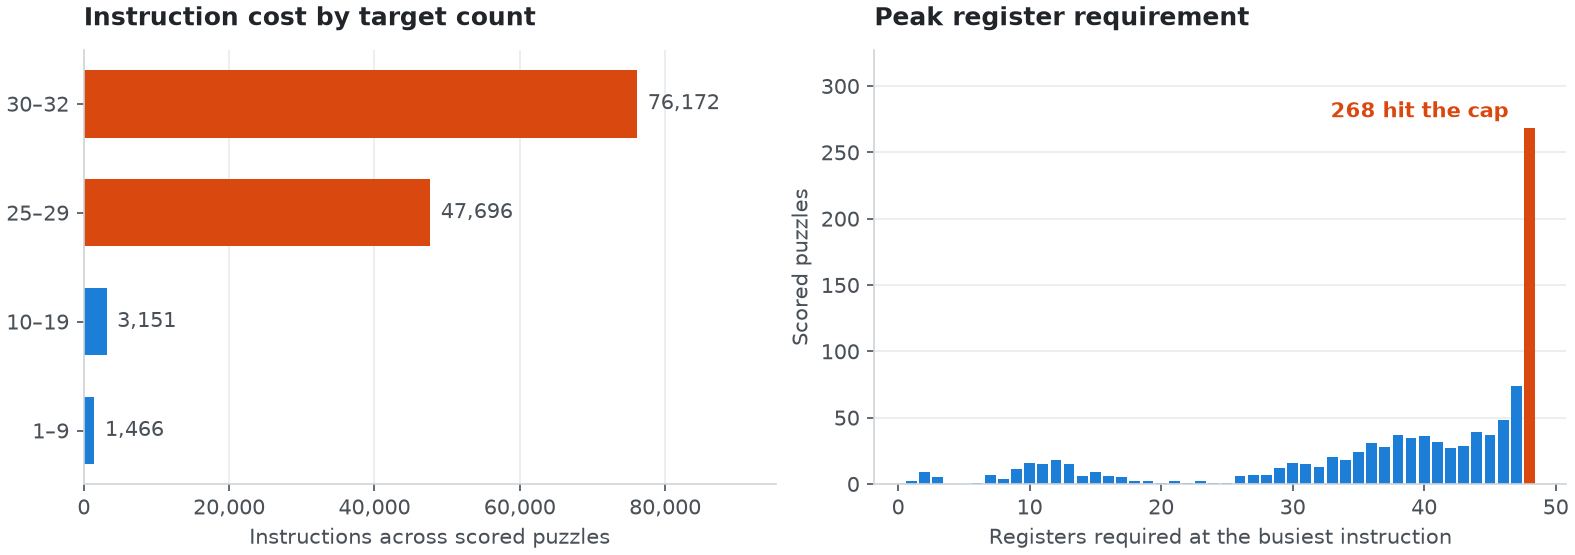

In [12]:
ReportFigures.style()
ReportFigures.portfolio(puzzles, baseline, peaks)

## 4 · Case study · scored_0771

The orange line shows the shorter graph in its original order. Orange shading marks the instructions that require one additional register. The replacement keeps one operand alive across a long portion of the tape.

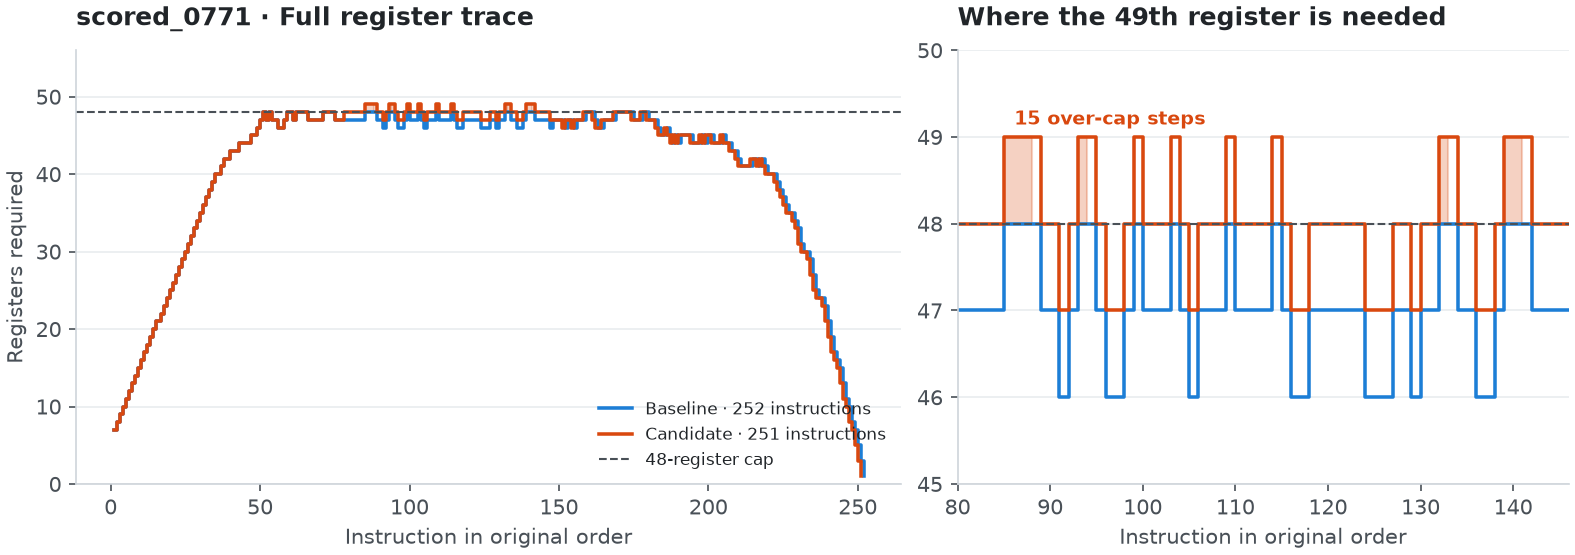

Same value: 48,387,354
Baseline recipe:  82,048,352 - 33,660,998
Candidate recipe: 82,048,350 - 33,660,996
Original-order pressure: 49 registers at peak · 15 over-cap steps


In [13]:
ReportFigures.case(case, puzzles[CASE_ID].register_count)
old_operator, old_a, old_b = case['old']
new_operator, new_a, new_b = case['new']
print(f"Same value: {case['value']:,}")
print(f'Baseline recipe:  {old_a:,} {old_operator} {old_b:,}')
print(f'Candidate recipe: {new_a:,} {new_operator} {new_b:,}')
overflow = sum(n > puzzles[CASE_ID].register_count for n in case['candidate'])
print(f'Original-order pressure: {max(case["candidate"])} registers at peak · {overflow} over-cap steps')

## 5 · Scheduling result and submission

The optional CP-SAT run assigns a position to each instruction and enforces a capacity constraint on register lifetimes. A timeout leaves the scheduling question open.

In [14]:
if RUN_CP_SAT:
    for rewrite, already_allocated in evidence:
        if already_allocated:
            continue
        pid = rewrite.puzzle_id
        status, order = ConstraintScheduler.solve(
            rewrite, puzzles[pid], radius=CP_RADIUS, seconds=CP_SECONDS,
        )
        print(f'{pid}: CP-SAT {status} · radius {CP_RADIUS} · budget {CP_SECONDS}s')
        if order is not None:
            tape = ConstraintScheduler.compile(rewrite, puzzles[pid], order)
            if tape is None:
                raise RuntimeError('The certified order could not be allocated')
            portfolio.calculator.replay(puzzles[pid], tape)
            if len(tape) < len(winners[pid]):
                winners[pid] = tape

improved = [(pid, len(baseline[pid]), len(tape)) for pid, tape in winners.items()
            if len(tape) < len(baseline[pid])]
savings = sum(before - after for _, before, after in improved)
print(f'Local score: {EXPECTED_SCORE - savings:,} | Saved: {savings:,} | Puzzles improved: {len(improved):,}')
for pid, before, after in sorted(improved):
    print(f'{pid}: {before} → {after}')
if improved:
    portfolio.export(winners, puzzles)
    print(f'Verified CSV: {portfolio.config.output_csv}')
else:
    print('No shorter valid portfolio was found. This run exported no submission CSV.')

Local score: 128,485 | Saved: 0 | Puzzles improved: 0
No shorter valid portfolio was found. This run exported no submission CSV.


## 6 · Experiment log

| Local search | Coverage | Outcome |
|:---|:---|:---|
| One-operation rewrites across the value graph | All 1,000 programs | One shorter graph; neither tested compiler order produced a legal tape |
| Bounded three-operation chain synthesis | 699 puzzles with a replaceable chain and at least 90 instructions | No candidate under the tested recipe limits |
| Exhaustive forward search for short programs | 17 puzzles, 1.25 s per puzzle | 11 searches exhausted their search space and 6 hit the time limit; no shorter program |
| CP-SAT scheduling for scored_0771 | Move radius 32 for 45 s, then 100 for 75 s | No feasible witness in either run; both returned UNKNOWN |

The two highest target-count bands contribute 123,868 instructions, or 96.4% of the score. For the next round, the highest-value test is on that group: choose arithmetic recipes jointly with the register schedule so an extra lifetime is priced before a replacement is accepted.